# Text-Level Bias: Data Exploration

## Project Overview

This notebook explores the Text-Level Bias task from the Media Bias Identification Benchmark (MBIB).

The goal is to understand the dataset, assess its quality, explore the text characteristics, and define the problem and its relevance.

In [1]:

from datasets import load_dataset
from pathlib import Path

# Load the MBIB dataset
ds = load_dataset("mediabiasgroup/mbib-base")

# Select the Text-Level Bias task
text_bias_df = ds["text_level_bias"].to_pandas()

# Create the data folder if it does not exist
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Save the task as a CSV file
file_path = data_dir / "text_level_bias.csv"
text_bias_df.to_csv(file_path, index=False)

print("Dataset shape:", text_bias_df.shape)
print("Saved to:", file_path)

Dataset shape: (9018, 4)
Saved to: /Users/a./Documents/GitHub/BiasLens/data/text_level_bias.csv


## 1. Dataset Overview

This section examines the dataset structure, features, label distribution, and basic statistics.

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(file_path)

display(df.head())
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nLabel distribution:")
display(df["label"].value_counts().sort_index())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

,id,text,label,dataset_id
0,076-27461,Conservatives and fascists kill people Antifa ...,1,76
1,076-14487,I don t see how you can discount the accuracy ...,0,76
2,076-10304,Snapshots 1 This Post archive org i redd ...,0,76
3,076-22865,critiques of leftist ideology Do you really...,1,76
4,076-22208,I can t deny that those same antifa faggots th...,1,76


Dataset shape: (9018, 4)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9018 entries, 0 to 9017
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          9018 non-null   object
 1   text        9018 non-null   object
 2   label       9018 non-null   int64 
 3   dataset_id  9018 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 281.9+ KB

Label distribution:


label
0    4509
1    4509
Name: count, dtype: int64


Descriptive statistics:


,id,text,label,dataset_id
count,9018,9018,9018.000000,9018.000000
unique,9018,9018,NaN,NaN
top,076-16943,Wow Fuck all those people And then Reddit will...,NaN,NaN
freq,1,1,NaN,NaN
mean,NaN,NaN,0.500000,73.338989
std,NaN,NaN,0.500028,12.025502
min,NaN,NaN,0.000000,19.000000
25%,NaN,NaN,0.000000,76.000000
50%,NaN,NaN,0.500000,76.000000
75%,NaN,NaN,1.000000,76.000000


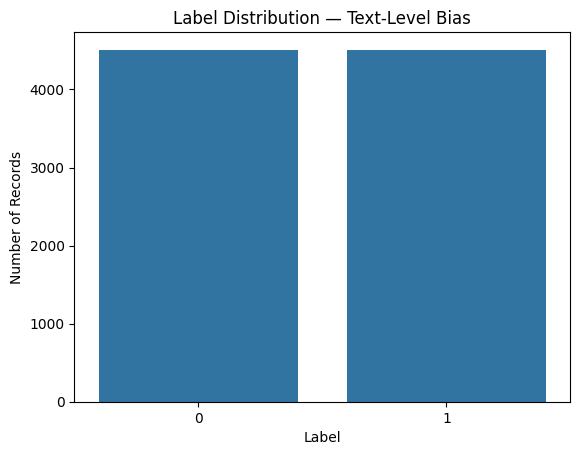

In [3]:
sns.countplot(data=df, x="label")
plt.title("Label Distribution — Text-Level Bias")
plt.xlabel("Label")
plt.ylabel("Number of Records")
plt.show()

* The dataset contains 9,018 records.
* The two classes are balanced, with 4,509 records per class.
* The balanced label distribution provides a useful starting point for binary classification.

## 2. Text Exploration

This section explores text length and the variation in text content to understand the characteristics of the dataset.

In [4]:
df["text"] = df["text"].fillna("").astype(str)

df["word_count"] = df["text"].str.split().str.len()
df["char_count"] = df["text"].str.len()

display(df[["word_count", "char_count"]].describe())

,word_count,char_count
count,9018.000000,9018.000000
mean,34.494899,186.471058
std,68.253431,373.085981
min,1.000000,2.000000
25%,8.000000,45.000000
50%,17.000000,93.000000
75%,36.000000,197.000000
max,1862.000000,10484.000000


### Text Length Statistics by Label

Compare the word count and character count of unbiased (0) and biased (1) texts using descriptive statistics.

In [31]:
# Compare text lengths for each label
length_stats = df.groupby("label")[["word_count", "char_count"]].describe()

display(length_stats)

word_count                                                       \
           count       mean        std  min   25%   50%   75%     max   
label                                                                   
0         4509.0  28.188290  45.397034  1.0   7.0  16.0  31.0   873.0   
1         4509.0  40.801508  84.720954  1.0  10.0  20.0  43.0  1862.0   

      char_count                                                            
           count        mean         std  min   25%    50%    75%      max  
label                                                                       
0         4509.0  151.501442  242.438416  2.0  38.0   83.0  171.0   4281.0  
1         4509.0  221.440674  466.041307  3.0  50.0  106.0  232.0  10484.0

* **25%:** A quarter of the texts have counts at or below this value.
* **50% (Median):** Half of the texts have counts at or below this value.
* **75%:** Three-quarters of the texts have counts at or below this value.

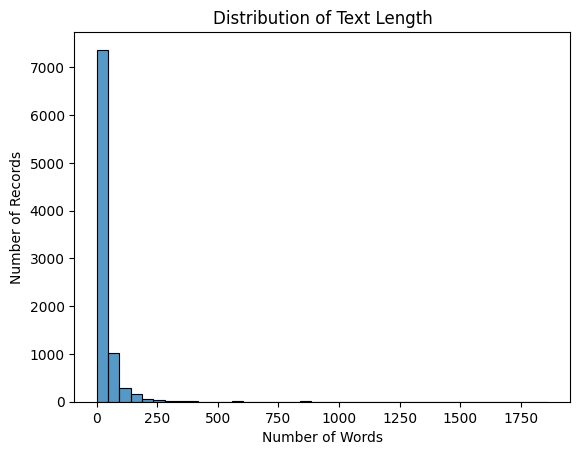

In [5]:
sns.histplot(data=df, x="word_count", bins=40)
plt.title("Distribution of Text Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Records")
plt.show()

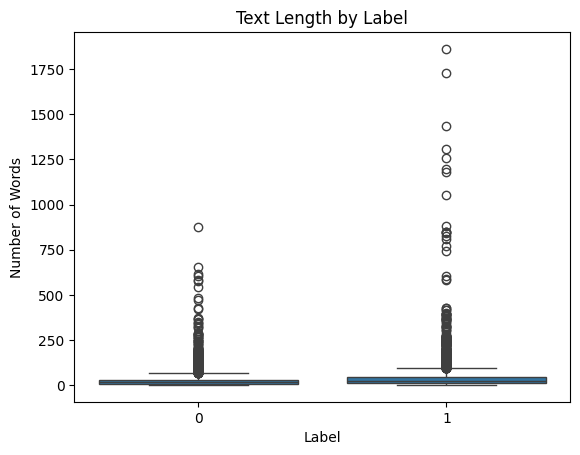

In [6]:
sns.boxplot(data=df, x="label", y="word_count")
plt.title("Text Length by Label")
plt.xlabel("Label")
plt.ylabel("Number of Words")
plt.show()

* Text lengths vary across records, with some texts substantially longer than others.
* The distribution helps identify unusually long texts and potential outliers.
* Comparing text length across labels can reveal whether the classes differ in their text characteristics. Length differences alone do not establish bias.

## 3. Data Quality Assessment

This section checks for missing values, empty texts, duplicate records, and conflicting labels for identical texts.

In [7]:
# Missing values
print("Missing values per column:")
display(df.isna().sum())

# Empty or whitespace-only texts
empty_texts = df["text"].str.strip().eq("").sum()
print("Empty texts:", empty_texts)

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Repeated texts
valid_df = df[df["text"].str.strip().ne("")].copy()
valid_df["text_clean"] = valid_df["text"].str.strip()

print(
    "Repeated text records:",
    valid_df["text_clean"].duplicated().sum()
)

# Conflicting labels for the same cleaned text
label_counts = valid_df.groupby("text_clean")["label"].nunique()
conflicts = label_counts[label_counts > 1]

print("Texts with conflicting labels:", len(conflicts))

Missing values per column:


id            0
text          0
label         0
dataset_id    0
word_count    0
char_count    0
dtype: int64

Empty texts: 0
Exact duplicate rows: 0
Repeated text records: 2
Texts with conflicting labels: 1


In [9]:
missing = df.isna().sum()
missing = missing[missing > 0]

if not missing.empty:
    missing.sort_values().plot(kind="barh")
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.show()
else:
    print("No missing values found.")

No missing values found.


* Missing and empty text records should be identified before model training.
* Duplicate texts may affect evaluation if identical or near-identical examples appear across training and test sets.
* Conflicting labels for the same text may indicate annotation ambiguity and should be investigated before deciding whether to remove any records.

* No missing values or empty texts were found.
* No exact duplicate rows were identified.
* Two repeated text records were found.
* One text was found with conflicting labels, indicating a potential annotation inconsistency that should be reviewed before modeling.

In [10]:
display(
    valid_df[valid_df["text_clean"].isin(conflicts.index)]
    [["id", "text", "label", "dataset_id"]]
    .sort_values("text")
)

,id,text,label,dataset_id
3290,076-7794,no,0,76
1534,076-22524,no,1,76


* A short text ("no") appears with conflicting labels (0 and 1), highlighting a potential annotation ambiguity.
* This record should be reviewed before modeling; no records were removed during the initial exploration.

## 4. Problem Definition and Domain

**Problem:** Text-level bias identification is a binary text classification task that aims to determine whether a text is labeled as biased or non-biased according to the dataset's annotation guidelines.

**Domain:** Natural Language Processing (NLP), text classification, and media bias analysis.

**Why it matters:** Identifying biased language can support media analysis and help researchers examine potential bias in written content. However, automated predictions may be affected by context, ambiguity, and limitations in the dataset annotations.

**Project objective:** Explore the dataset and establish a baseline for identifying text-level bias using machine learning.

**Label Definition:** The dataset uses binary labels, where 0 represents unbiased text and 1 represents biased text.

**Problem:** Binary text classification to identify biased and unbiased content.

**Domain:** Natural Language Processing (NLP) and media bias analysis.

**Objective:** Explore the dataset's text characteristics and data quality before building a machine learning model.

## 5. Privacy and Fairness Considerations

**Privacy:** The dataset should be checked for personal or sensitive information before sharing examples or using the data in a public presentation.

**Fairness:** Bias labels may involve subjective judgments and ambiguous language. The model may also produce different error rates across topics or groups.

**Limitation:** Dataset labels should not automatically be treated as objective or universally correct judgments.

In [11]:
from pathlib import Path

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report = """# Text-Level Bias — EDA Findings

## Dataset Overview
- Total records: 9,018
- Label 0: 4,509 records
- Label 1: 4,509 records
- Class distribution: Balanced

## Data Quality
- Missing values: 0
- Empty texts: 0
- Exact duplicate rows: 0
- Repeated text records: 2
- Texts with conflicting labels: 1

## Example of a Label Conflict
The text "no" appears with both label 0 and label 1.
This may indicate annotation ambiguity and should be reviewed.

## Evaluation Plan
- Data split: 80% train, 10% validation, 10% test
- Main metric: F1-score
- Supporting metrics: Precision, Recall, and Confusion Matrix

## Notes for the Presentation
- Include the label distribution plot.
- Include the text length distribution plot.
- Include the text length by label plot.
- Discuss duplicate-text handling and potential label ambiguity.
- Check that identical texts do not cross dataset splits.
"""

report_path = reports_dir / "text_level_bias_findings.md"
report_path.write_text(report, encoding="utf-8")

print("Findings saved to:", report_path)

Findings saved to: /Users/a./Documents/GitHub/BiasLens/reports/text_level_bias_findings.md


## Additional Duplicate Check

This section checks for duplicate texts after removing leading and trailing whitespace and normalizing repeated spaces within the text.

In [12]:
# Keep the original text unchanged
duplicate_check_df = df.copy()

# Normalize whitespace for comparison
duplicate_check_df["text_normalized"] = (
    duplicate_check_df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude empty texts
valid_texts = duplicate_check_df[
    duplicate_check_df["text_normalized"].ne("")
].copy()

# Count repeated normalized texts
repeated_count = valid_texts["text_normalized"].duplicated().sum()

# Count unique texts that appear more than once
text_frequencies = valid_texts["text_normalized"].value_counts()
repeated_unique_texts = (text_frequencies > 1).sum()

print("Repeated text records:", repeated_count)
print("Unique texts appearing more than once:", repeated_unique_texts)

# Check conflicting labels after whitespace normalization
label_counts = valid_texts.groupby("text_normalized")["label"].nunique()
conflicting_texts = label_counts[label_counts > 1]

print("Texts with conflicting labels:", len(conflicting_texts))

Repeated text records: 2
Unique texts appearing more than once: 2
Texts with conflicting labels: 1


* No missing values or empty texts were found.
* No exact duplicate rows were identified.
* Two repeated texts were identified after whitespace normalization.
* One text has conflicting labels (0 and 1), indicating a potential annotation inconsistency.